Parte I - Regressão Linear

In [1]:
# preparação dos dados
import pandas as pd
from reg_linear import separar_sequencias, construir_matrizes

df = pd.read_pickle("Xsup.pkl")
seq_treino, seq_teste = separar_sequencias(df)
Xtreino, Ytreino = construir_matrizes(seq_treino)

In [2]:
# R2.a
from reg_linear import regressao_linear

beta, beta0 = regressao_linear(Xtreino, Ytreino)

print("Dimensão de beta:", beta.shape)
print("Dimensão de beta0:", beta0.shape)


Dimensão de beta: (66, 66)
Dimensão de beta0: (66,)


In [3]:
# R2.b
from reg_linear import avaliar_regressao

Y_previsto_treino = Xtreino[:, :-1] @ beta + beta0

sse_treino, r2_treino = avaliar_regressao(Ytreino, Y_previsto_treino)

print("SSE treino:", sse_treino)
print("R2 treino:", r2_treino)

SSE treino: 1.4344932286470555
R2 treino: 0.9666172418890806


In [4]:
# R2.c
import numpy as np

Xteste, Yteste = construir_matrizes(seq_teste)

Y_previsto_teste = Xteste[:, :-1] @ beta + beta0

sse_teste, r2_teste = avaliar_regressao(Yteste, Y_previsto_teste)

print("SSE teste:", sse_teste)
print("R2 teste:", r2_teste)

# SSE por keypoint (33 keypoints, 2 coordenadas cada)
sse_keypoints = ((Yteste - Y_previsto_teste)**2).reshape(-1, 33, 2).sum(axis=(0, 2))

for i in np.argsort(sse_keypoints)[-5:][::-1]:
    print(f"Keypoint {i}: {sse_keypoints[i]:.4f}")

SSE teste: 0.7344378383838099
R2 teste: 0.9290939107816183
Keypoint 31: 0.0819
Keypoint 29: 0.0712
Keypoint 27: 0.0681
Keypoint 26: 0.0637
Keypoint 25: 0.0473


In [8]:
# R2.d
from IPython.display import display
from funcoes_aux_proj_apr_supervisionada import visualize_sequences

Xseq, Yseq = construir_matrizes(seq_teste.iloc[[0]])
Yseq_previsto = Xseq[:, :-1] @ beta + beta0

display(visualize_sequences(Yseq, "Sequência verdadeira"))
display(visualize_sequences(Yseq_previsto, "Sequência prevista"))

Total Frames to Animate: 34


Total Frames to Animate: 34


Parte II -  ́Arvores de Decisão

In [ ]:
# R4.a
from arvore_decisao import ArvoreDecisao, avaliar_classificacao

arvores = {}

for profundidade in range(1, 6):
    arvore = ArvoreDecisao(profundidade_maxima=profundidade)
    arvore.fit(Xtrain, ytrain)

    arvores[profundidade] = arvore

    _, acc_treino = avaliar_classificacao(ytrain, arvore.predict(Xtrain))
    _, acc_teste = avaliar_classificacao(ytest, arvore.predict(Xtest))

    print(f"Profundidade {profundidade}: Treino = {acc_treino:.4f}, Teste = {acc_teste:.4f}")

Profundidade 1: Treino = 0.3889, Teste = 0.4000
Profundidade 2: Treino = 0.7489, Teste = 0.7600
Profundidade 3: Treino = 0.9667, Teste = 0.9100
Profundidade 4: Treino = 1.0000, Teste = 0.9100
Profundidade 5: Treino = 1.0000, Teste = 0.9100


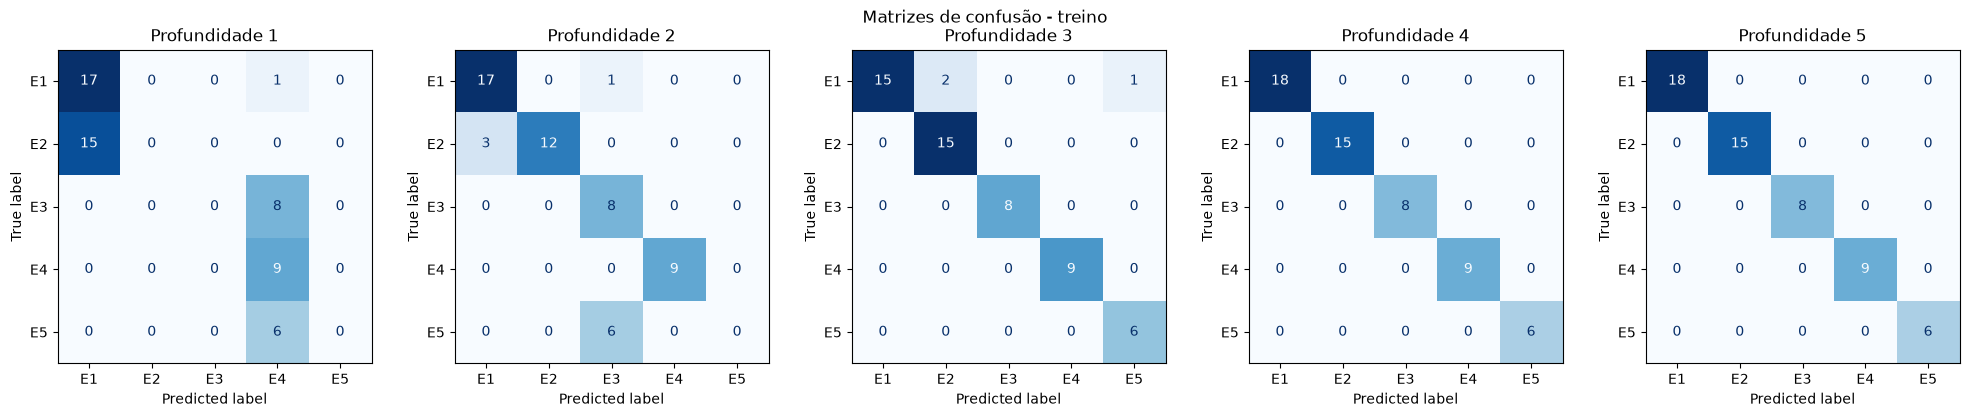

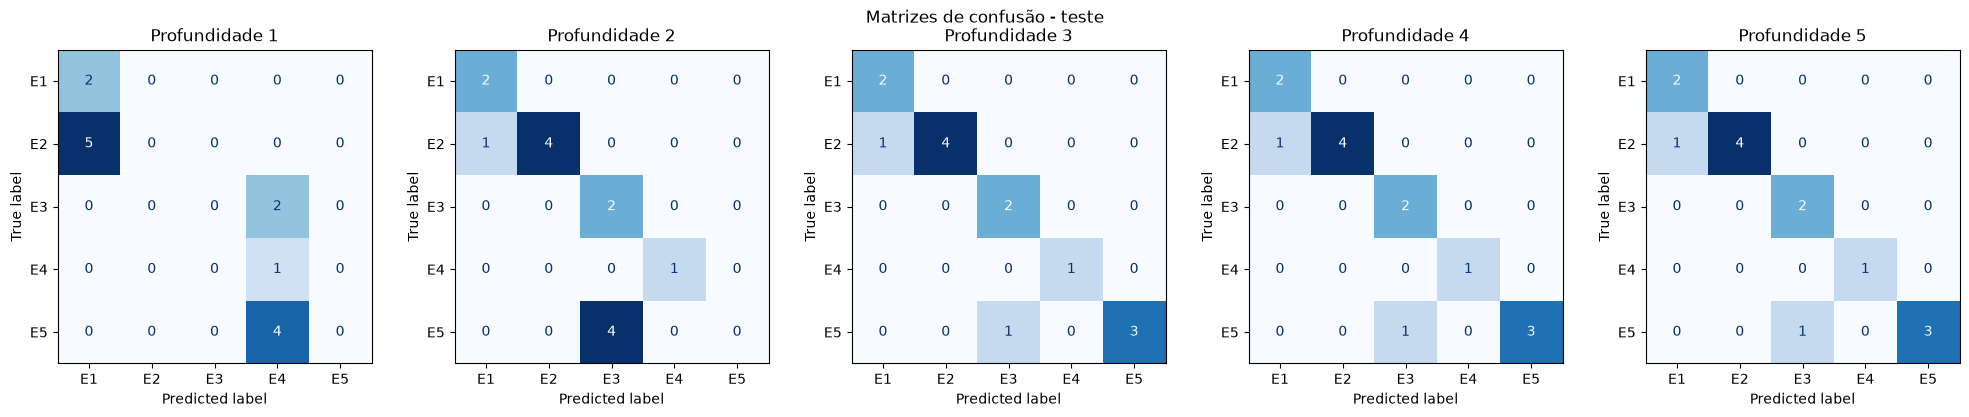

In [ ]:
# R4.b
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for nome, X, y in [("treino", Xtrain, ytrain), ("teste", Xtest, ytest)]:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    for profundidade, ax in zip(range(1, 6), axes):
        matriz, _ = avaliar_classificacao(y, arvores[profundidade].predict(X))

        ConfusionMatrixDisplay(matriz, display_labels=["E1", "E2", "E3", "E4", "E5"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"Profundidade {profundidade}")

    fig.suptitle(f"Matrizes de confusão - {nome}")
    fig.tight_layout()
    fig.savefig(f"matrizes_{nome}.png", dpi=200, bbox_inches="tight")
    plt.show()


In [20]:
# R4.c
from funcoes_aux_proj_apr_supervisionada import imprimir_arvore, obter_nomes_atributos

nomes = obter_nomes_atributos()
classes = {i: f"E{i+1}" for i in range(5)}

imprimir_arvore(arvores[4].raiz, nomes_atributos=nomes, idx_to_class=classes)

├── [cotovelo_esquerdo_desvio_padrao_vel_y <= 0.006416]
  [Verdadeiro]
    ├── [amplitude_movimento_joelho_esquerdo <= 11.538988]
      [Verdadeiro]
        ├── [cotovelo_esquerdo_desvio_padrao_vel_x <= 0.004645]
          [Verdadeiro]
            ├── [orelha_esquerda_media_vel_x <= -0.000051]
              [Verdadeiro]
                └── Folha: E1
              [Falso]
                └── Folha: E2
          [Falso]
            └── Folha: E1
      [Falso]
        └── Folha: E2
  [Falso]
    ├── [nariz_desvio_padrao_vel_y <= 0.010464]
      [Verdadeiro]
        ├── [punho_direito_desvio_padrao_vel_y <= 0.012200]
          [Verdadeiro]
            ├── [ombro_esquerdo_media_vel_y <= -0.001206]
              [Verdadeiro]
                └── Folha: E1
              [Falso]
                └── Folha: E5
          [Falso]
            └── Folha: E3
      [Falso]
        └── Folha: E4
